<a href="https://colab.research.google.com/github/myhanafi/NLP-3/blob/main/KDD_SDAE_LSTM_multiclass_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!ls
!rm -f kddcup.data.gz
!rm -f corrected.gz
!rm -f kddcup.data_10_percent.gz
!wget http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data.gz
!wget http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz
!wget http://kdd.ics.uci.edu/databases/kddcup99/corrected.gz

corrected  kddcup.data	kddcup.data_10_percent	sample_data
--2021-11-10 07:35:33--  http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data.gz
Resolving kdd.ics.uci.edu (kdd.ics.uci.edu)... 128.195.1.86
Connecting to kdd.ics.uci.edu (kdd.ics.uci.edu)|128.195.1.86|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 18115902 (17M) [application/x-gzip]
Saving to: ‘kddcup.data.gz’

kddcup.data.gz      100%[===================>]  17.28M  4.38MB/s    in 4.8s    

2021-11-10 07:35:38 (3.62 MB/s) - ‘kddcup.data.gz’ saved [18115902/18115902]

--2021-11-10 07:35:38--  http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz
Resolving kdd.ics.uci.edu (kdd.ics.uci.edu)... 128.195.1.86
Connecting to kdd.ics.uci.edu (kdd.ics.uci.edu)|128.195.1.86|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2144903 (2.0M) [application/x-gzip]
Saving to: ‘kddcup.data_10_percent.gz’

kddcup.data_10_perc 100%[===================>]   2.04M  2.16MB/s    in 0.9s    

In [ ]:
!gunzip -f kddcup.data.gz
!gunzip -f corrected.gz
!gunzip -f kddcup.data_10_percent.gz
!ls

corrected  kddcup.data	kddcup.data_10_percent	sample_data


In [ ]:
import pandas as pd
import numpy as np
import sklearn
from sklearn.utils.random import sample_without_replacement
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn import preprocessing
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras.layers import Dense, Dropout, Input
from keras import Sequential, Model
from keras import backend as K
from keras.datasets import mnist
from keras.utils.np_utils import to_categorical
import tensorflow as tf

In [ ]:
columns = ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
           'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
           'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
           'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
           'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
           'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
           'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
           'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
           'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
           'dst_host_srv_rerror_rate', 'attack_type']
print("columns length = ", len(columns))

attack_categories = {
    'probe': [
          'portsweep', 'ipsweep', 'nmap', 'satan'
    ],
    'dos': [
          'neptune', 'smurf', 'pod', 'teardrop', 'land', 'back'
    ],
    'u2r': [
           'buffer_overflow', 'loadmodule', 'perl', 'rootkit'
    ],
    'r2l': [
           'guess_passwd', 'ftp_write', 'imap', 'phf', 'multihop', 'warezmaster', 'warezclient', 'spy'
    ],
    'normal': ['normal']
}
symbolic_columns = ['protocol_type', 'service', 'flag']
target_columns = ['attack_type', 'attack_flag', 'attack_category']
attack_type_list = "back,buffer_overflow,ftp_write,guess_passwd,imap,ipsweep,land,loadmodule,multihop,neptune,nmap,normal,perl,phf,pod,portsweep,rootkit,satan,smurf,spy,teardrop,warezclient,warezmaster".split(',')
kdd_train_filename = './kddcup.data'
kdd_train_10_percent_filename = './kddcup.data_10_percent'
kdd_test_filename = './corrected'

columns length =  42


In [ ]:
# helper functions

def attack_category_to_attack_type(cat):
  results = {}
  for c in cat:
    for t in cat[c]:
      results[t] = c
  return results

In [ ]:
def load_data(filename, columns, attack_categories):
  categories_map = attack_category_to_attack_type(attack_categories)
  categories_index = list(attack_categories.keys())
  df = pd.read_csv(filename, header=None)
  df.columns = columns
  df['attack_type'] = df['attack_type'].apply(lambda x: x[:-1]) # normalize attack types

  # filter for attack type
  # some attack_type in test set doesn't exist in train set
  df = df[df.attack_type.isin(attack_type_list)]

  # add attack_flag column
  df.loc[df.attack_type == 'normal', 'attack_flag'] = np.int(0)
  df.loc[df.attack_type != 'normal', 'attack_flag'] = np.int(1)

  # add attack_category column
  df['attack_category'] = df.attack_type.apply(lambda ac: categories_map[ac])

  return df

In [ ]:
df = load_data(kdd_train_filename, columns, attack_categories)
df

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,attack_flag,attack_category
0,0,tcp,http,SF,215,45076,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.0,0.0,0.0,1.0,0.0,0.00,0,0,0.0,0.0,0.00,0.00,0.0,0.00,0.0,0.0,normal,0.0,normal
1,0,tcp,http,SF,162,4528,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.0,0.0,0.00,1,1,1.0,0.0,1.00,0.00,0.0,0.00,0.0,0.0,normal,0.0,normal
2,0,tcp,http,SF,236,1228,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.0,0.0,0.0,1.0,0.0,0.00,2,2,1.0,0.0,0.50,0.00,0.0,0.00,0.0,0.0,normal,0.0,normal
3,0,tcp,http,SF,233,2032,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.0,0.0,0.00,3,3,1.0,0.0,0.33,0.00,0.0,0.00,0.0,0.0,normal,0.0,normal
4,0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,3,3,0.0,0.0,0.0,0.0,1.0,0.0,0.00,4,4,1.0,0.0,0.25,0.00,0.0,0.00,0.0,0.0,normal,0.0,normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4898426,0,tcp,http,SF,212,2288,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,3,32,0.0,0.0,0.0,0.0,1.0,0.0,0.16,3,255,1.0,0.0,0.33,0.05,0.0,0.01,0.0,0.0,normal,0.0,normal
4898427,0,tcp,http,SF,219,236,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,4,33,0.0,0.0,0.0,0.0,1.0,0.0,0.15,4,255,1.0,0.0,0.25,0.05,0.0,0.01,0.0,0.0,normal,0.0,normal
4898428,0,tcp,http,SF,218,3610,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,34,0.0,0.0,0.0,0.0,1.0,0.0,0.15,5,255,1.0,0.0,0.20,0.05,0.0,0.01,0.0,0.0,normal,0.0,normal
4898429,0,tcp,http,SF,219,1234,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,6,35,0.0,0.0,0.0,0.0,1.0,0.0,0.14,6,255,1.0,0.0,0.17,0.05,0.0,0.01,0.0,0.0,normal,0.0,normal


In [ ]:
df.groupby('attack_category').size()

# nparr = df.to_numpy()
# nparr



attack_category
dos       3883370
normal     972781
probe       41102
r2l          1126
u2r            52
dtype: int64

In [ ]:
def normalize_features(train_set, test_set=None):
  cutting_point = train_set.shape[0]

  # combine
  combined_df = pd.concat([train_set, test_set] if test_set else [train_set])

  # encoding symbolic columns
  tmp_df = pd.get_dummies(combined_df[symbolic_columns])

  tmp = pd.concat([combined_df, tmp_df], axis=1)
  tmp = tmp.loc[:, ~tmp.columns.isin(symbolic_columns)]

  return (tmp.iloc[:cutting_point], tmp.iloc[cutting_point:]) if test_set else tmp

train_set = normalize_features(df)
train_set

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,attack_flag,...,service_nnsp,service_nntp,service_ntp_u,service_other,service_pm_dump,service_pop_2,service_pop_3,service_printer,service_private,service_red_i,service_remote_job,service_rje,service_shell,service_smtp,service_sql_net,service_ssh,service_sunrpc,service_supdup,service_systat,service_telnet,service_tftp_u,service_tim_i,service_time,service_urh_i,service_urp_i,service_uucp,service_uucp_path,service_vmnet,service_whois,flag_OTH,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,0,215,45076,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.0,0.0,0.0,1.0,0.0,0.00,0,0,0.0,0.0,0.00,0.00,0.0,0.00,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,0,162,4528,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.0,0.0,0.00,1,1,1.0,0.0,1.00,0.00,0.0,0.00,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,0,236,1228,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.0,0.0,0.0,1.0,0.0,0.00,2,2,1.0,0.0,0.50,0.00,0.0,0.00,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
3,0,233,2032,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.0,0.0,0.00,3,3,1.0,0.0,0.33,0.00,0.0,0.00,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,0,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,3,3,0.0,0.0,0.0,0.0,1.0,0.0,0.00,4,4,1.0,0.0,0.25,0.00,0.0,0.00,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4898426,0,212,2288,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,3,32,0.0,0.0,0.0,0.0,1.0,0.0,0.16,3,255,1.0,0.0,0.33,0.05,0.0,0.01,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4898427,0,219,236,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,4,33,0.0,0.0,0.0,0.0,1.0,0.0,0.15,4,255,1.0,0.0,0.25,0.05,0.0,0.01,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4898428,0,218,3610,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,34,0.0,0.0,0.0,0.0,1.0,0.0,0.15,5,255,1.0,0.0,0.20,0.05,0.0,0.01,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4898429,0,219,1234,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,6,35,0.0,0.0,0.0,0.0,1.0,0.0,0.14,6,255,1.0,0.0,0.17,0.05,0.0,0.01,0.0,0.0,normal,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


In [ ]:
# sampling for multiclass labels
intended_classes = ['normal', 'dos', 'probe', 'r2l', 'u2r']
intended_classes_num_records = {
    'normal': 41102,
    'dos': 41102,
    'probe': 41102,
    'r2l': 1126,
    'u2r' :52,
}
# normal_records = train_set.loc[train_set.attack_type == 'normal']
# attacked_records = train_set.loc[~(train_set.attack_type == 'normal')]
selected_records_by_class = {}
for iclass in intended_classes:
  selected_records_by_class[iclass] = train_set.loc[train_set.attack_category == iclass]

def sampling_data(df, n_samples):
  index = sample_without_replacement(len(df), n_samples)
  return df.iloc[index].reset_index(drop=True)

records_by_category = map(lambda ct: sampling_data(selected_records_by_class[ct],
                                                   intended_classes_num_records[ct]),
                          intended_classes)
# normal_records_sampled = sampling_data(normal_records, 100000)
# attacked_records_sampled = sampling_data(attacked_records, 100148)
sampled_df = pd.concat(records_by_category).sample(frac=1).reset_index(drop=True)

# convert attack_category to index
sampled_df['attack_category'] = sampled_df.attack_category.apply(lambda x: intended_classes.index(x))
_X = sampled_df.iloc[:, ~sampled_df.columns.isin(['attack_type', 'attack_flag', 'attack_category'])]
_y = sampled_df.attack_category
sampled_df.groupby('attack_category').size()

attack_category
0    41102
1    41102
2    41102
3     1126
4       52
dtype: int64

In [ ]:
# normalize the inputs
input_columns = _X.columns
minmax = preprocessing.MinMaxScaler()
_X = minmax.fit_transform(_X)
_X = pd.DataFrame(_X)
_X.columns = input_columns
_X

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,protocol_type_icmp,protocol_type_tcp,...,service_nnsp,service_nntp,service_ntp_u,service_other,service_pm_dump,service_pop_2,service_pop_3,service_printer,service_private,service_red_i,service_remote_job,service_rje,service_shell,service_smtp,service_sql_net,service_ssh,service_sunrpc,service_supdup,service_systat,service_telnet,service_tftp_u,service_tim_i,service_time,service_urh_i,service_urp_i,service_uucp,service_uucp_path,service_vmnet,service_whois,flag_OTH,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,0.000000,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.001957,0.23,0.0,0.77,1.0,0.00,1.00,0.00,1.000000,0.003922,0.00,1.00,0.00,0.00,0.18,0.0,0.82,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.000000,2.231942e-07,2.459660e-06,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003914,0.003914,0.00,0.0,0.00,0.0,1.00,0.00,0.00,1.000000,0.980392,0.98,0.01,0.00,0.00,0.00,0.0,0.00,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.000000,2.463833e-07,1.832149e-07,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007828,0.007828,0.00,0.0,0.00,0.0,1.00,0.00,0.00,0.078431,1.000000,1.00,0.00,0.05,0.03,0.00,0.0,0.00,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.000000,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.414873,0.007828,1.00,1.0,0.00,0.0,0.02,0.07,0.00,1.000000,0.011765,0.01,0.08,0.00,0.00,1.00,1.0,0.00,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.000000,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.577299,0.046967,1.00,1.0,0.00,0.0,0.08,0.05,0.00,1.000000,0.094118,0.09,0.05,0.00,0.00,1.00,1.0,0.00,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124479,0.000000,7.478457e-07,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,1.000000,0.00,0.0,0.00,0.0,1.00,0.00,0.00,1.000000,1.000000,1.00,0.00,1.00,0.00,0.00,0.0,0.00,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
124480,0.000069,6.007404e-07,2.526838e-07,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.001957,0.001957,0.00,0.0,0.00,0.0,1.00,0.00,0.00,0.470588,0.674510,0.77,0.03,0.01,0.01,0.00,0.0,0.00,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0

In [ ]:
# split the data into train, validation and test set
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.4, random_state=0) # split train | (val&test)
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.5, random_state=0) # split val | test
for train_index, tmp_index in sss1.split(_X, _y):
  X_train = _X.loc[train_index].reset_index(drop=True)
  y_train = _y.loc[train_index].reset_index(drop=True)

  X_tmp = _X.loc[tmp_index].reset_index(drop=True)
  y_tmp = _y.loc[tmp_index].reset_index(drop=True)
  # split tmp to val and test
  for val_index, test_index in sss2.split(X_tmp, y_tmp):
    X_val = X_tmp.loc[val_index].reset_index(drop=True)
    y_val = y_tmp.loc[val_index].reset_index(drop=True)
    X_test = X_tmp.loc[test_index].reset_index(drop=True)
    y_test = y_tmp.loc[test_index].reset_index(drop=True)


In [ ]:
# convert label to categorical
y_train = tf.keras.utils.to_categorical(y_train, num_classes=len(intended_classes))
y_val = tf.keras.utils.to_categorical(y_val, num_classes=len(intended_classes))
y_test = tf.keras.utils.to_categorical(y_test, num_classes=len(intended_classes))

In [ ]:
class SDAE:
  def __init__(self, n_layers=1, n_hidden=[100], dropouts=[0.1],  optimizer='adam', loss='mean_squared_error', batch_size=32):
    assert n_layers, len(n_hidden)
    assert n_layers, len(dropouts)
    self.n_layers = n_layers
    self.batch_size = batch_size
    self.optimizer = optimizer
    self.loss = loss
    self.n_hidden = n_hidden
    self.dropouts=dropouts
    self._pre_trained_model = None

  def train_model(self, X, y, validation_data=None, epochs=1):

    # noise is provided by dropout

    input_dim = X.shape[1]

    encoders = []
    # train layer by layer
    for cur_layer in range(self.n_layers):
      model = Sequential()

      # input
      input = Input(shape=(X.shape[1],))
      model.add(input)

      model.add(Dropout(self.dropouts[cur_layer]))
      encoder = Dense(self.n_hidden[cur_layer], activation='sigmoid', name="encoder-"+str(cur_layer))
      model.add(encoder)

      n_out = X.shape[1]

      model.add(Dense(n_out, activation='sigmoid', name="decoder-"+str(cur_layer)))

      print("Training layer " + str(cur_layer))

      # model.summary()

      # compile model
      model.compile(optimizer=self.optimizer, loss=self.loss)

      model.fit(X, X, epochs=epochs, validation_data=validation_data, batch_size=self.batch_size)

      print("Layer " + str(cur_layer) + " has been trained")

      X = self.get_layer_output(model, X, cur_layer)
      X_val = self.get_layer_output(model, validation_data[0], cur_layer)
      validation_data = (X_val, X_val)

      encoders.append(encoder)

    return self._build_pre_trained_model(encoders, input_dim)

  def _build_pre_trained_model(self, encoders, input_dim):
    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    model.add(Dropout(self.dropouts[0]))

    for i in range(len(encoders)):
      model.add(encoders[i])

    self._pre_trained_model = model
    # model.summary()
    return model

  def get_layer_output(self, model, X, layer_num, training=False):
    # func = K.function([model.input, K.learning_phase()], [model.get_layer("encoder-" + str(layer_num)).output])
    partial_model = Model(model.inputs, model.get_layer("encoder-" + str(layer_num)).output)

    return partial_model(X, training=training)

In [ ]:
sdae = SDAE(n_layers=2, n_hidden=[90, 50], dropouts=[0.1, 0.1])
enc = sdae.train_model(X_train, y_train, validation_data=(X_val, X_val), epochs=10)#10

# reduce dimension
X_train = enc.predict(X_train)
X_val = enc.predict(X_val)
X_test = enc.predict(X_test)

Training layer 0
Epoch 1/10
2335/2335 [==============================] - 14s 5ms/step - loss: 0.0113 - val_loss: 0.0020
Epoch 2/10
2335/2335 [==============================] - 11s 5ms/step - loss: 0.0019 - val_loss: 9.4879e-04
Epoch 3/10
2335/2335 [==============================] - 10s 4ms/step - loss: 0.0014 - val_loss: 7.1897e-04
Epoch 4/10
2335/2335 [==============================] - 10s 4ms/step - loss: 0.0012 - val_loss: 5.7009e-04
Epoch 5/10
2335/2335 [==============================] - 10s 4ms/step - loss: 0.0010 - val_loss: 4.9317e-04
Epoch 6/10
2335/2335 [==============================] - 10s 4ms/step - loss: 9.6950e-04 - val_loss: 4.4523e-04
Epoch 7/10
2335/2335 [==============================] - 10s 4ms/step - loss: 9.0860e-04 - val_loss: 4.0302e-04
Epoch 8/10
2335/2335 [==============================] - 11s 5ms/step - loss: 8.7631e-04 - val_loss: 3.7311e-04
Epoch 9/10
2335/2335 [==============================] - 11s 5ms/step - loss: 8.3759e-04 - val_loss: 3.6074e-04
Epoch 10

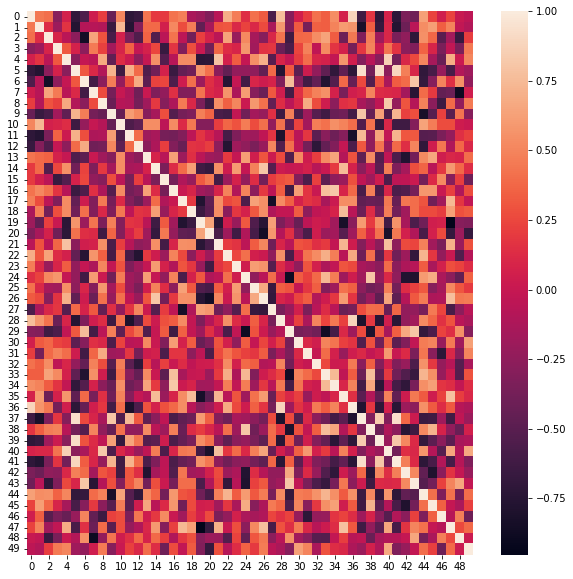

In [ ]:
# Correlation matrix
corr_df = pd.DataFrame(data=X_train, columns=list(range(X_train.shape[1])))
corr_matrix = corr_df.corr()
figure = plt.figure(figsize=(10, 10))
sns.heatmap(corr_matrix, annot=False)
plt.show()

In [ ]:
# Keras version
from keras.models import Sequential
from keras.layers import Dense, BatchNormalization, Dropout
import keras
from keras import layers
import tensorflow as tf
import keras.backend as K

def create_model_dropout(n_inputs):

  inputs = keras.Input(shape=(n_inputs,), name="input")
  batch = layers.BatchNormalization()(inputs)
  layer1 = layers.Dense(256, activation="sigmoid", name="dense1")(batch)
  drop = layers.Dropout(0.5)(layer1)
  layer11 = layers.Dense(56, activation="relu", name="dense3")(drop)
  drop = layers.Dropout(0.5)(layer11)
  layer2 = layers.Dense(256, activation="sigmoid", name="dense2")(drop)
  batch = layers.BatchNormalization()(layer2)
  outputs = layers.Dense(1, activation="sigmoid", name="out")(batch)

  return keras.Model(inputs=inputs, outputs=outputs)

def create_model_lstm(n_inputs):

  inputs = keras.Input(shape=(n_inputs,), name="input")
  batch = layers.BatchNormalization()(inputs)
  reshape = layers.Reshape((1, n_inputs))(batch)

  lstm1 = layers.LSTM(64, return_sequences=True)(reshape)
  drop1 = layers.Dropout(0.1)(lstm1)

  lstm2 = layers.LSTM(64, return_sequences=True)(drop1)
  drop2 = layers.Dropout(0.1)(lstm2)

  lstm3 = layers.LSTM(64)(lstm2)
  drop3 = layers.Dropout(0.1)(lstm3)
  layer2 = layers.Dense(256, activation="sigmoid", name="dense2")(drop3)
  batch = layers.BatchNormalization()(layer2)
  outputs = layers.Dense(len(intended_classes), activation="softmax", name="out")(batch)

  return keras.Model(inputs=inputs, outputs=outputs)

def recall(y_true, y_pred):
  c_labels = tf.argmax(y_true, axis=1)
  c_preds = tf.argmax(y_pred, axis=1)
  cm = tf.math.confusion_matrix(c_labels, c_preds)

  diag_part = tf.linalg.tensor_diag_part(cm)
  sum_col = tf.math.reduce_sum(cm, axis=1)

  return tf.math.reduce_mean(tf.math.divide(diag_part, sum_col))
  # i = tf.sets(y_true).intersection(y_pred)
  # return tf.size(i) / tf.size(y_true)
  # true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
  # possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
  # recall = true_positives / (possible_positives + K.epsilon())
  # return recall

def precision(y_true, y_pred):
  c_labels = tf.argmax(y_true, axis=1)
  c_preds = tf.argmax(y_pred, axis=1)
  cm = tf.math.confusion_matrix(c_labels, c_preds)

  diag_part = tf.linalg.tensor_diag_part(cm)
  sum_row = tf.math.reduce_sum(cm, axis=0)

  return tf.math.reduce_mean(tf.math.divide(diag_part, sum_row))
  # print(y_true)
  # i = tf.sets(y_true).intersection(y_pred)
  # len1 = tf.size(y_pred)
  # if len1 == 0:
  #   return 0
  # else:
  #   return tf.size(i) / len1
  # true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
  # predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
  # precision = true_positives / (predicted_positives + K.epsilon())
  # return precision

In [ ]:
model1 = create_model_lstm(X_train.shape[1])
model1.summary()

Model: "model_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 50)]              0         
                                                                 
 batch_normalization_2 (Batc  (None, 50)               200       
 hNormalization)                                                 
                                                                 
 reshape_1 (Reshape)         (None, 1, 50)             0         
                                                                 
 lstm_3 (LSTM)               (None, 1, 64)             29440     
                                                                 
 dropout_6 (Dropout)         (None, 1, 64)             0         
                                                                 
 lstm_4 (LSTM)               (None, 1, 64)             33024     
                                                           

In [ ]:
model1.compile(loss=tf.keras.losses.categorical_crossentropy, optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
               metrics=['accuracy', precision, recall])

In [ ]:
history = model1.fit(X_train, y_train, batch_size=128, epochs=20, validation_data=(X_val, y_val)) #20

Epoch 1/20
584/584 [==============================] - 22s 21ms/step - loss: 0.0599 - accuracy: 0.9865 - precision: nan - recall: nan - val_loss: 0.0349 - val_accuracy: 0.9939 - val_precision: nan - val_recall: nan
Epoch 2/20
584/584 [==============================] - 11s 18ms/step - loss: 0.0245 - accuracy: 0.9932 - precision: nan - recall: nan - val_loss: 0.0181 - val_accuracy: 0.9954 - val_precision: nan - val_recall: nan
Epoch 3/20
584/584 [==============================] - 10s 18ms/step - loss: 0.0216 - accuracy: 0.9941 - precision: nan - recall: nan - val_loss: 0.0245 - val_accuracy: 0.9932 - val_precision: nan - val_recall: nan
Epoch 4/20
584/584 [==============================] - 10s 18ms/step - loss: 0.0207 - accuracy: 0.9940 - precision: nan - recall: nan - val_loss: 0.0181 - val_accuracy: 0.9945 - val_precision: nan - val_recall: nan
Epoch 5/20
584/584 [==============================] - 11s 18ms/step - loss: 0.0177 - accuracy: 0.9951 - precision: nan - recall: nan - val_loss:

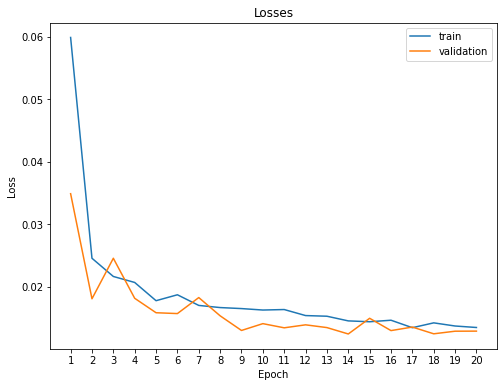

In [ ]:
# plot the history of losses over time
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['train', 'validation'], loc='upper right')
plt.xticks(np.arange(len(history.history['loss'])), labels=np.arange(1, len(history.history['loss'])+1))
plt.title('Losses')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

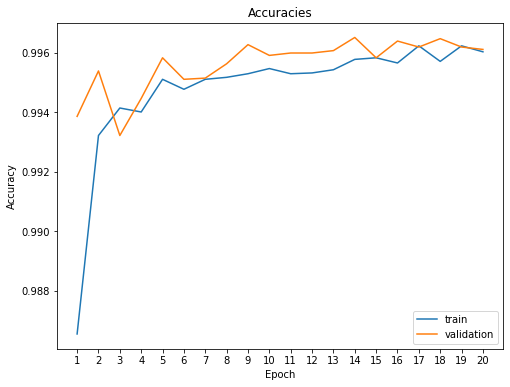

In [ ]:
# plot the history of accuracy over time
plt.figure(figsize=(8, 6))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['train', 'validation'], loc='lower right')
plt.xticks(np.arange(len(history.history['accuracy'])), labels=np.arange(1, len(history.history['accuracy'])+1))
plt.title('Accuracies')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.show()

In [ ]:
test_eval_res = model1.evaluate(X_test, y_test)

(loss_test, accuracy_test, precision_test, recall_test) = test_eval_res

# F1 dihitung dengan rumus F1 = 2 * (precision * recall) / (precision + recall)
f1_test = 2 * (precision_test * recall_test) / (precision_test + recall_test)
print("Accuracy = ", accuracy_test)
print("Precision = ", precision_test)
print("Recall = ", recall_test)
print("F1 = ", f1_test)

779/779 [==============================] - 8s 10ms/step - loss: 0.0163 - accuracy: 0.9956 - precision: nan - recall: nan
Accuracy =  0.9955818057060242
Precision =  nan
Recall =  nan
F1 =  nan


In [ ]:
pred = model1.predict(X_test)
pred

array([[1.2147820e-05, 9.9981457e-01, 1.5619196e-04, 1.6715780e-05,
        4.0476630e-07],
       [2.6419370e-06, 9.9993873e-01, 5.6451401e-05, 2.1554060e-06,
        2.4842450e-08],
       [9.9992192e-01, 8.5327374e-06, 3.4170560e-05, 3.4775298e-05,
        6.3562652e-07],
       ...,
       [9.9991333e-01, 9.2989130e-06, 3.9685972e-05, 3.6994745e-05,
        7.0312905e-07],
       [2.6419370e-06, 9.9993873e-01, 5.6451401e-05, 2.1554060e-06,
        2.4842450e-08],
       [2.6478792e-06, 9.9993849e-01, 5.6720073e-05, 2.1588678e-06,
        2.4961711e-08]], dtype=float32)

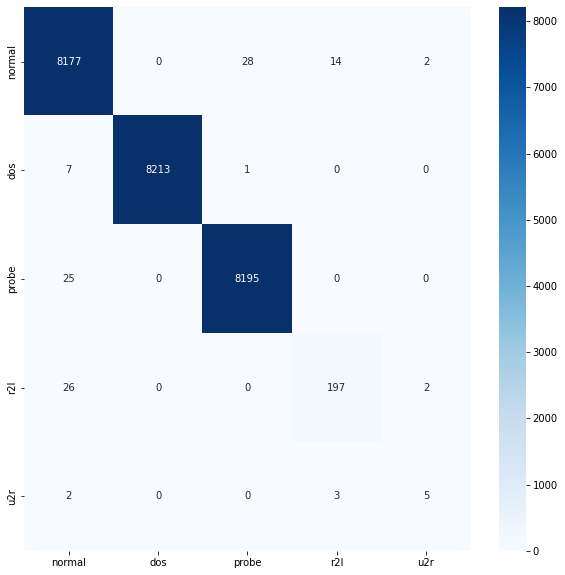

In [ ]:
list_of_labels = intended_classes
pred_labeled = pred.argmax(axis=1)
pred_labeled = np.vectorize(lambda i: list_of_labels[i])(pred_labeled)
test_labeled = y_test.argmax(axis=1)
test_labeled = np.vectorize(lambda i: list_of_labels[i])(test_labeled)

from sklearn.metrics import confusion_matrix

confmat = confusion_matrix(test_labeled, pred_labeled, labels=list_of_labels)

figure = plt.figure(figsize=(10, 10))
sns.heatmap(confmat, xticklabels=list_of_labels, yticklabels=list_of_labels, annot=True, fmt='d', cmap='Blues')